Tahap 1 : Melakukan Load Data Set ke Project

In [3]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

# Membaca dataset
df = pd.read_csv('/content/dataset_tugas1_preprocessing.csv')
print(df.head())

      ID  Nama Jenis_Kelamin            Prodi Status Nilai_Akhir  \
0  MH001  Iwan     Laki-laki  Teknik Komputer  Aktif         NaN   
1  MH002   Eka     Perempuan  Teknik Komputer  Lulus           E   
2  MH003  Iwan     Laki-laki  Teknik Komputer  Aktif         NaN   
3  MH004   Eka     Perempuan  Teknik Komputer  Aktif           D   
4  MH005  Joko     Perempuan     Data Science  Aktif           C   

  Tanggal_Ujian  Umur  
0    13-04-2020   NaN  
1    2020/12/11  28.0  
2    2021/11/21  23.0  
3    2021/08/19  18.0  
4    2020/01/05  26.0  


Tahap 2: Eksplorasi Awal (EDA)

In [4]:
# Cek info struktur dan tipe data
print(df.info())

# Cek jumlah missing values
print(df.isnull().sum())

# Statistik deskriptif
print(df.describe(include='all'))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99 entries, 0 to 98
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   ID             99 non-null     object 
 1   Nama           99 non-null     object 
 2   Jenis_Kelamin  99 non-null     object 
 3   Prodi          99 non-null     object 
 4   Status         99 non-null     object 
 5   Nilai_Akhir    70 non-null     object 
 6   Tanggal_Ujian  99 non-null     object 
 7   Umur           90 non-null     float64
dtypes: float64(1), object(7)
memory usage: 6.3+ KB
None
ID                0
Nama              0
Jenis_Kelamin     0
Prodi             0
Status            0
Nilai_Akhir      29
Tanggal_Ujian     0
Umur              9
dtype: int64
           ID Nama Jenis_Kelamin            Prodi Status Nilai_Akhir  \
count      99   99            99               99     99          70   
unique     99   10             2                4      4           5   
top     MH00

**Penjelasan**


1.   Struktur dan Tipe Data: Dataset terdiri dari 99 baris dan 8 kolom. Tipe data awal meliputi 7 kolom bertipe object (ID, Nama, Jenis_Kelamin, Prodi, Status, Nilai_Akhir, Tanggal_Ujian) dan 1 kolom numerik bertipe float64 (Umur).
  
2.   Jumlah Nilai Hilang (Missing Values):

  *   Nilai_Akhir: 29 data kosong
  *   Umur: 9 data kosong
  * Kolom lainnya (ID, Nama, Jenis_Kelamin, Prodi, Status, Tanggal_Ujian): 0 data kosong


3. Statistik Deskriptif:

* Rentang Umur berkisar antara 18 hingga 30 tahun, dengan nilai rata-rata 23,37 tahun dan median 23 tahun.

* Mahasiswa terdistribusi ke dalam 4 program studi: Teknik Komputer (28), Informatika (28), Sistem Informasi (23), dan Data Science (20).

Tahap 3: Menangani Missing Values

In [5]:
# Imputasi Nilai_Akhir dengan modus
modus_nilai = df['Nilai_Akhir'].mode()[0]
df['Nilai_Akhir'] = df['Nilai_Akhir'].fillna(modus_nilai)

# Imputasi Umur dengan median
median_umur = df['Umur'].median()
df['Umur'] = df['Umur'].fillna(median_umur)

# Verifikasi missing values telah bersih
print(df.isnull().sum())

ID               0
Nama             0
Jenis_Kelamin    0
Prodi            0
Status           0
Nilai_Akhir      0
Tanggal_Ujian    0
Umur             0
dtype: int64


**Penjelasan**
* Kolom Nilai_Akhir: Merupakan variabel kategorikal (kategori A, B, C, D, E), sehingga metode yang tepat adalah imputasi menggunakan modus (kategori yang paling sering muncul, yaitu 'C').

* Kolom Umur: Merupakan variabel numerik diskret, sehingga diimputasi menggunakan median (nilai tengah = 23) agar tidak terpengaruh oleh potensi pencilan (outlier).

Tahap 4: Normalisasi Format Tanggal

Kolom Tanggal_Ujian memiliki format campuran (seperti DD-MM-YYYY dan YYYY/MM/DD). Konversi dilakukan menggunakan pd.to_datetime dengan parameter format='mixed'.

In [6]:
df['Tanggal_Ujian'] = pd.to_datetime(df['Tanggal_Ujian'], format='mixed')
print(df['Tanggal_Ujian'].dtype)  # Hasil: datetime64[ns]

datetime64[ns]


Tahap 5: Encoding Label

Proses transformasi data kategorikal ke representasi numerik menggunakan LabelEncoder untuk kolom Nama, Jenis_Kelamin, Prodi, Status, dan Nilai_Akhir.

In [7]:
kolom_kategori = ['Nama', 'Jenis_Kelamin', 'Prodi', 'Status', 'Nilai_Akhir']
label_encoders = {}

for col in kolom_kategori:
  le = LabelEncoder()
  df[col] = le.fit_transform(df[col])
  label_encoders[col] = le

print(df.head())

      ID  Nama  Jenis_Kelamin  Prodi  Status  Nilai_Akhir Tanggal_Ujian  Umur
0  MH001     8              0      3       0            2    2020-04-13  23.0
1  MH002     4              1      3       3            4    2020-12-11  28.0
2  MH003     8              0      3       0            2    2021-11-21  23.0
3  MH004     4              1      3       0            3    2021-08-19  18.0
4  MH005     9              1      0       0            2    2020-01-05  26.0


Tahap 6: Split Data

Dataset dipisahkan menjadi data latih (training set) sebesar 80% (79 baris) dan data uji (testing set) sebesar 20% (20 baris).


In [8]:
# Pemisahan dataset (80% latih, 20% uji)
train_df, test_df = train_test_split(df, test_size=0.2, random_state=42)

print(f'Ukuran Data Latih: {train_df.shape}')  # (79, 8)
print(f'Ukuran Data Uji   : {test_df.shape}')  # (20, 8)

Ukuran Data Latih: (79, 8)
Ukuran Data Uji   : (20, 8)


Tahap 7: Visualisasi

Visualisasi dibuat untuk memeriksa distribusi frekuensi umur serta sebaran mahasiswa per program studi:

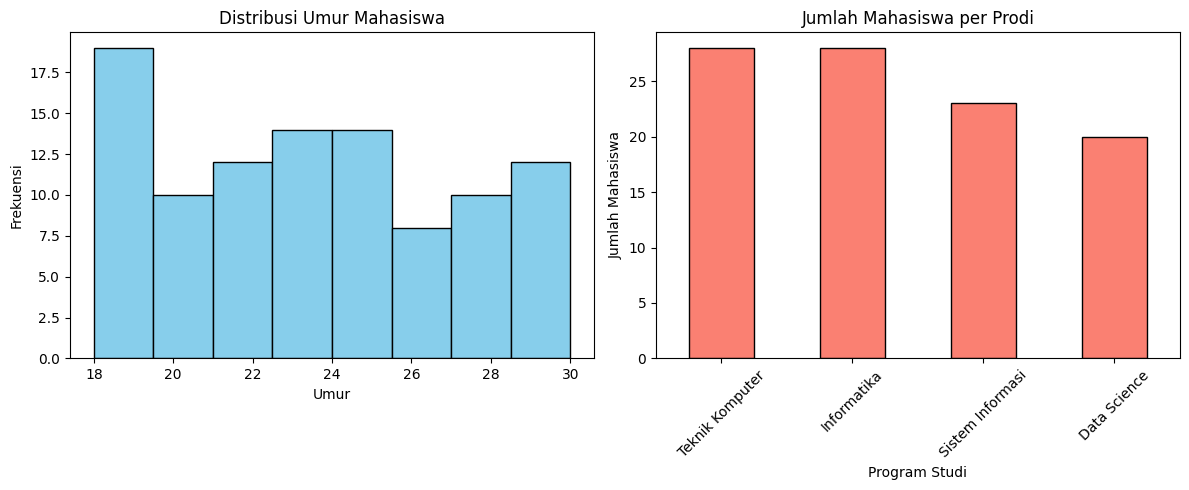

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# 1. Histogram kolom Umur
axes[0].hist(df['Umur'], bins=8, color='skyblue', edgecolor='black')
axes[0].set_title('Distribusi Umur Mahasiswa')
axes[0].set_xlabel('Umur')
axes[0].set_ylabel('Frekuensi')

# 2. Grafik batang per Prodi (mengambil data decoding nama prodi)
nama_prodi = label_encoders['Prodi'].inverse_transform(df['Prodi'])
pd.Series(nama_prodi).value_counts().plot(
    kind='bar', ax=axes[1], color='salmon', edgecolor='black'
)
axes[1].set_title('Jumlah Mahasiswa per Prodi')
axes[1].set_xlabel('Program Studi')
axes[1].set_ylabel('Jumlah Mahasiswa')
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()